# SpecSynth AI — Insulation Dataset Audit (v1.0)

**Purpose:** Audit the insulation-only subset before training or tuning any model.

This notebook does not modify the source CSV, train models, impute source values, or create synthetic records.

**Dataset:** `SpecSynth_ML_variants_v1.5.0.csv`  
**Expected filter:** `material_category_group == "A_thermal_insulation"`

Run this notebook using the `arch_ai` kernel. Review every output before proceeding to model training.


In [1]:
from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 160)

PROJECT_ROOT = Path(r"D:\\02_LEARNING\\02_Masters_IAAC_AI_Architecture\\10-Term_01\\03-Research Studio\\SpecSynth_AI")
DATASET_PATH = (
    PROJECT_ROOT
    / "04_Product_Dataset"
    / "10_Master_Database"
    / "SpecSynth_Master_Database_v1.0"
    / "source_data"
    / "v1.5.0"
    / "ml"
    / "SpecSynth_ML_variants_v1.5.0.csv"
)

# Optional alternative: set this to the CSV's actual location if your project is stored elsewhere.
# DATASET_PATH = Path(r"C:\\path\\to\\SpecSynth_ML_variants_v1.5.0.csv")

print("Dataset path:", DATASET_PATH)
print("File exists:", DATASET_PATH.exists())
if not DATASET_PATH.exists():
    raise FileNotFoundError(
        "CSV not found. Update DATASET_PATH to the actual location of "
        "SpecSynth_ML_variants_v1.5.0.csv and rerun this cell."
    )

df = pd.read_csv(DATASET_PATH, low_memory=False)
print(f"Loaded dataset: {df.shape[0]:,} rows × {df.shape[1]} columns")
display(df.head())


Dataset path: D:\02_LEARNING\02_Masters_IAAC_AI_Architecture\10-Term_01\03-Research Studio\SpecSynth_AI\04_Product_Dataset\10_Master_Database\SpecSynth_Master_Database_v1.0\source_data\v1.5.0\ml\SpecSynth_ML_variants_v1.5.0.csv
File exists: True
Loaded dataset: 1,941 rows × 47 columns


,record_id,product_id,variant_id,material_category_group,material_family,category,manufacturer,market,record_origin,dataset_version_added,thickness_mm,thermal_resistance_m2K_W,r_status,thermal_conductivity_W_mK,lambda_level,density_kg_m3,specific_heat_J_kgK,vapour_resistance_factor_mu,compressive_strength_kPa,tensile_strength_perpendicular_kPa,reaction_to_fire,euroclass_main,mass_per_area_kg_m2,Ug_W_m2K,gwp_a1_a3_kgco2e_m2,gwp_fossil_a1_a3_kgco2e_m2,gwp_a1_a3_kgco2e_m3,gwp_a1_a3_kgco2e_kg,gwp_status,gwp_declared_unit,epd_number,price_per_m2,price_currency,price_type,price_date,data_status,evidence_quality_score,qa_flag_count,qa_flags,source_ids,split_group_id,target_thermal_conductivity_W_mK,target_density_kg_m3,target_specific_heat_J_kgK,target_gwp_a1_a3_kgco2e_m2,target_price_per_m2,recommended_split
0,ML_UNILIN_UTHERM_WALL_A_40MM,UNILIN_UTHERM_WALL_A,UNILIN_UTHERM_WALL_A_40MM,A_thermal_insulation,PIR,PIR insulation board,UNILIN Insulation,NaN,legacy_v1.2.0,1.2.0,40.0,1.80,manufacturer_declared,0.022,product,32.0,NaN,NaN,150.0,80.0,"D-s2,d0",D,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,VERIFIED,3,0,NaN,SRC_UNILIN_DOP;SRC_UNILIN_TDS,UNILIN_UTHERM_WALL_A,0.022,32.0,NaN,NaN,NaN,train
1,ML_UNILIN_UTHERM_WALL_A_50MM,UNILIN_UTHERM_WALL_A,UNILIN_UTHERM_WALL_A_50MM,A_thermal_insulation,PIR,PIR insulation board,UNILIN Insulation,NaN,legacy_v1.2.0,1.2.0,50.0,2.25,manufacturer_declared,0.022,product,32.0,NaN,NaN,150.0,80.0,"D-s2,d0",D,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,VERIFIED,3,0,NaN,SRC_UNILIN_DOP;SRC_UNILIN_TDS,UNILIN_UTHERM_WALL_A,0.022,32.0,NaN,NaN,NaN,train
2,ML_UNILIN_UTHERM_WALL_A_60MM,UNILIN_UTHERM_WALL_A,UNILIN_UTHERM_WALL_A_60MM,A_thermal_insulation,PIR,PIR insulation board,UNILIN Insulation,NaN,legacy_v1.2.0,1.2.0,60.0,2.70,manufacturer_declared,0.022,product,32.0,NaN,NaN,150.0,80.0,"D-s2,d0",D,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,VERIFIED,3,0,NaN,SRC_UNILIN_DOP;SRC_UNILIN_TDS,UNILIN_UTHERM_WALL_A,0.022,32.0,NaN,NaN,NaN,train
3,ML_UNILIN_UTHERM_WALL_A_70MM,UNILIN_UTHERM_WALL_A,UNILIN_UTHERM_WALL_A_70MM,A_thermal_insulation,PIR,PIR insulation board,UNILIN Insulation,NaN,legacy_v1.2.0,1.2.0,70.0,3.15,manufacturer_declared,0.022,product,32.0,NaN,NaN,150.0,80.0,"D-s2,d0",D,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,VERIFIED,3,0,NaN,SRC_UNILIN_DOP;SRC_UNILIN_TDS,UNILIN_UTHERM_WALL_A,0.022,32.0,NaN,NaN,NaN,train
4,ML_UNILIN_UTHERM_WALL_A_80MM,UNILIN_UTHERM_WALL_A,UNILIN_UTHERM_WALL_A_80MM,A_thermal_insulation,PIR,PIR insulation board,UNILIN Insulation,NaN,legacy_v1.2.0,1.2.0,80.0,3.60,manufacturer_declared,0.022,product,32.0,NaN,NaN,150.0,80.0,"D-s2,d0",D,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,VERIFIED,3,0,NaN,SRC_UNILIN_DOP;SRC_UNILIN_TDS,UNILIN_UTHERM_WALL_A,0.022,32.0,NaN,NaN,NaN,train


## 1. Confirm dataset structure

**What we are checking:** the dataset schema, key identifiers, insulation filter column and group-split metadata.

**Decision rule:** stop if required identifiers or `material_category_group` are missing. We must not guess which records are insulation.


In [2]:
required_columns = [
    "record_id", "product_id", "variant_id",
    "material_category_group", "material_family",
    "category", "manufacturer", "split_group_id",
    "recommended_split"
]
missing_required = [c for c in required_columns if c not in df.columns]

schema_summary = pd.DataFrame({
    "column": df.columns,
    "dtype": [str(df[c].dtype) for c in df.columns],
    "missing_count": [int(df[c].isna().sum()) for c in df.columns],
    "missing_percent": [round(df[c].isna().mean() * 100, 2) for c in df.columns],
    "unique_non_null": [int(df[c].nunique(dropna=True)) for c in df.columns]
})

print("Missing required columns:", missing_required)
if missing_required:
    raise ValueError(f"Required columns missing: {missing_required}")

display(schema_summary)


Missing required columns: []


,column,dtype,missing_count,missing_percent,unique_non_null
0,record_id,str,0,0.00,1941
1,product_id,str,0,0.00,178
2,variant_id,str,0,0.00,1941
3,material_category_group,str,0,0.00,7
4,material_family,str,0,0.00,32
5,category,str,0,0.00,61
6,manufacturer,str,0,0.00,56
7,market,str,1424,73.36,18
8,record_origin,str,0,0.00,3
9,dataset_version_added,str,0,0.00,3


## 2. Filter insulation records

We use the explicit dataset group label `A_thermal_insulation`. We do not infer insulation membership from product names.

**Conclusion to record:** the number of insulation variants, products, manufacturers and material families. These counts establish the actual modelling population.


In [3]:
INSULATION_GROUP = "A_thermal_insulation"

group_counts = (
    df["material_category_group"]
    .fillna("<MISSING>")
    .value_counts()
    .rename_axis("material_category_group")
    .reset_index(name="records")
)
display(group_counts)

ins = df.loc[df["material_category_group"].eq(INSULATION_GROUP)].copy()

if ins.empty:
    raise ValueError(
        f"No rows found for material_category_group={INSULATION_GROUP!r}. "
        "Inspect group_counts and update the filter only if the dataset definition supports it."
    )

summary = pd.DataFrame({
    "metric": [
        "All dataset records",
        "Insulation records",
        "Insulation share (%)",
        "Unique insulation products",
        "Unique insulation variants",
        "Unique manufacturers",
        "Unique material families",
        "Unique categories",
        "Unique split groups"
    ],
    "value": [
        len(df),
        len(ins),
        round(len(ins) / len(df) * 100, 2),
        ins["product_id"].nunique(),
        ins["variant_id"].nunique(),
        ins["manufacturer"].nunique(),
        ins["material_family"].nunique(),
        ins["category"].nunique(),
        ins["split_group_id"].nunique()
    ]
})
display(summary)


,material_category_group,records
0,A_thermal_insulation,1674
1,F_envelope,79
2,G_glazing,66
3,E_boards,52
4,D_timber_biobased,35
5,B_masonry,24
6,C_concrete,11


,metric,value
0,All dataset records,1941.00
1,Insulation records,1674.00
2,Insulation share (%),86.24
3,Unique insulation products,70.00
4,Unique insulation variants,1674.00
5,Unique manufacturers,34.00
6,Unique material families,16.00
7,Unique categories,25.00
8,Unique split groups,69.00


## 3. Material-family and category balance

**Why this matters:** an insulation-only model can still be imbalanced. For example, a model may perform well on glass wool and poorly on a small specialist family.

We inspect record counts and independent product counts. Variant counts alone can exaggerate representation when many variants belong to the same product.


,material_family,records,products,manufacturers,split_groups,record_share_percent
0,glass_wool,416,24,6,24,24.85
1,EPS,366,6,3,6,21.86
2,PIR,187,7,4,7,11.17
3,XPS,179,8,4,8,10.69
4,stone_wool,151,7,4,7,9.02
5,cellulose,121,2,2,2,7.23
6,wood_wool_composite,47,1,1,1,2.81
7,cork,36,1,1,1,2.15
8,wood_fibre,34,3,2,3,2.03
9,polyester_wool,28,2,1,2,1.67


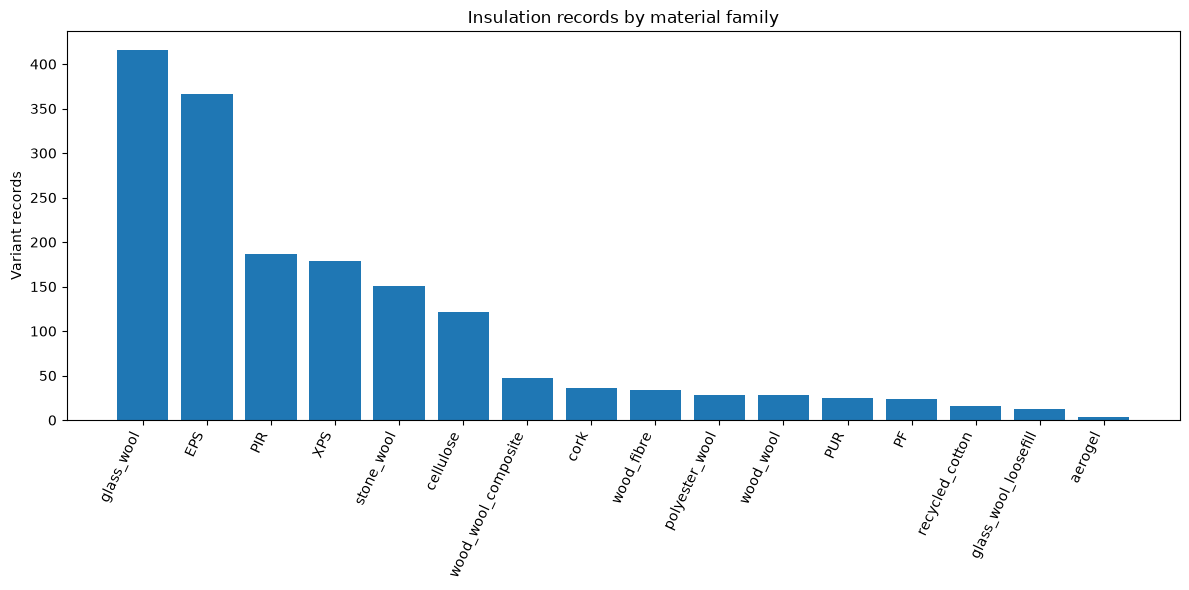

In [4]:
family_balance = (
    ins.groupby("material_family", dropna=False)
       .agg(
           records=("variant_id", "count"),
           products=("product_id", "nunique"),
           manufacturers=("manufacturer", "nunique"),
           split_groups=("split_group_id", "nunique")
       )
       .sort_values("records", ascending=False)
       .reset_index()
)
family_balance["record_share_percent"] = (
    family_balance["records"] / len(ins) * 100
).round(2)
display(family_balance)

plt.figure(figsize=(12, 6))
plt.bar(family_balance["material_family"].astype(str), family_balance["records"])
plt.xticks(rotation=65, ha="right")
plt.ylabel("Variant records")
plt.title("Insulation records by material family")
plt.tight_layout()
plt.show()


## 4. Manufacturer representation

**Why this matters:** many records from one manufacturer may make a model appear to generalise when it has mostly learned that manufacturer's product conventions.

We compare variant counts with unique product counts by manufacturer.


In [5]:
manufacturer_balance = (
    ins.groupby("manufacturer", dropna=False)
       .agg(
           records=("variant_id", "count"),
           products=("product_id", "nunique"),
           families=("material_family", "nunique")
       )
       .sort_values("records", ascending=False)
       .reset_index()
)
manufacturer_balance["record_share_percent"] = (
    manufacturer_balance["records"] / len(ins) * 100
).round(2)
display(manufacturer_balance.head(30))

print("Top 5 manufacturers' combined record share (%):",
      round(manufacturer_balance.head(5)["records"].sum() / len(ins) * 100, 2))


,manufacturer,records,products,families,record_share_percent
0,Hirsch France,299,4,1,17.86
1,Knauf Insulation SPRL,186,5,1,11.11
2,SOPREMA,141,4,1,8.42
3,ROCKWOOL France S.A.S.,135,4,1,8.06
4,"UNILIN BV, Division Insulation",121,3,1,7.23
5,URSA Insulation S.A.,88,9,3,5.26
6,Saint-Gobain Isover (FR),80,5,1,4.78
7,CAVAC Biomatériaux,62,1,1,3.70
8,IGLOO France Cellulose SAS,59,1,1,3.52
9,Etex France Building Performance,57,1,1,3.41


Top 5 manufacturers' combined record share (%): 52.69


## 5. Technical-property completeness

We separate:
- properties that are plausible model inputs,
- thermal conductivity as the main regression target,
- metadata and provenance fields.

Do not use target-derived or mathematically equivalent columns as regression inputs. In particular, do not use thermal resistance or thickness to predict conductivity when those values encode the same relationship in this dataset.


,property,available_records,missing_records,missing_percent,unique_values
0,thickness_mm,1674,0,0.00,218
1,thermal_resistance_m2K_W,1666,8,0.48,220
2,thermal_conductivity_W_mK,1614,60,3.58,20
10,target_thermal_conductivity_W_mK,1614,60,3.58,20
6,compressive_strength_kPa,607,1067,63.74,13
5,vapour_resistance_factor_mu,603,1071,63.98,6
7,tensile_strength_perpendicular_kPa,589,1085,64.81,9
8,mass_per_area_kg_m2,223,1451,86.68,155
11,target_density_kg_m3,163,1511,90.26,30
3,density_kg_m3,163,1511,90.26,30


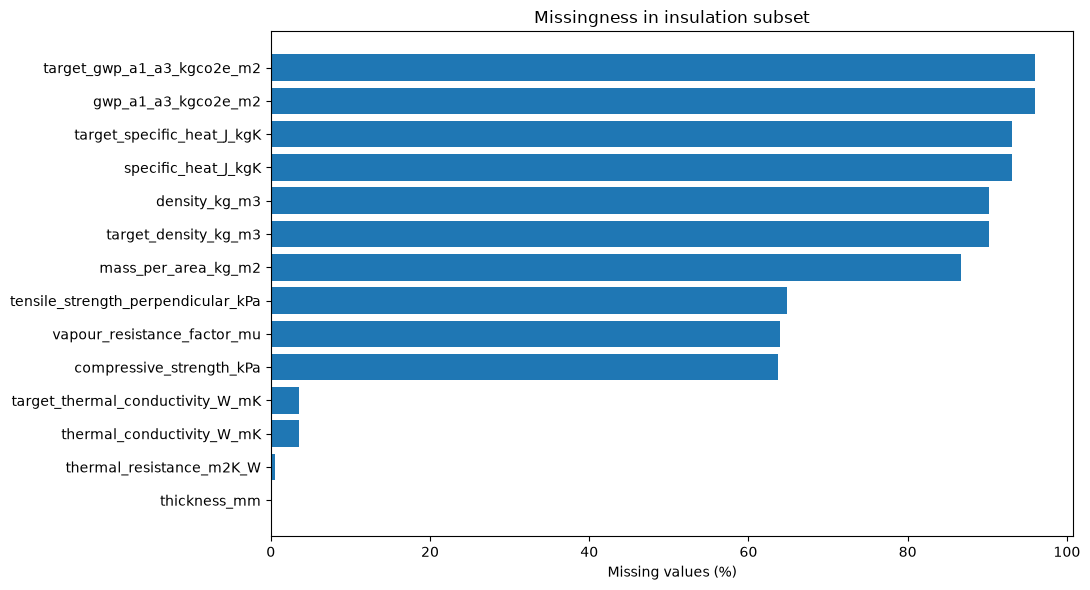

In [6]:
numeric_candidates = [
    "thickness_mm",
    "thermal_resistance_m2K_W",
    "thermal_conductivity_W_mK",
    "density_kg_m3",
    "specific_heat_J_kgK",
    "vapour_resistance_factor_mu",
    "compressive_strength_kPa",
    "tensile_strength_perpendicular_kPa",
    "mass_per_area_kg_m2",
    "gwp_a1_a3_kgco2e_m2",
    "target_thermal_conductivity_W_mK",
    "target_density_kg_m3",
    "target_specific_heat_J_kgK",
    "target_gwp_a1_a3_kgco2e_m2"
]
numeric_candidates = [c for c in numeric_candidates if c in ins.columns]

property_coverage = pd.DataFrame({
    "property": numeric_candidates,
    "available_records": [int(ins[c].notna().sum()) for c in numeric_candidates],
    "missing_records": [int(ins[c].isna().sum()) for c in numeric_candidates],
    "missing_percent": [round(ins[c].isna().mean() * 100, 2) for c in numeric_candidates],
    "unique_values": [int(ins[c].nunique(dropna=True)) for c in numeric_candidates]
}).sort_values("missing_percent")

display(property_coverage)

plt.figure(figsize=(11, 6))
plot_cov = property_coverage.sort_values("missing_percent", ascending=True)
plt.barh(plot_cov["property"], plot_cov["missing_percent"])
plt.xlabel("Missing values (%)")
plt.title("Missingness in insulation subset")
plt.tight_layout()
plt.show()


## 6. Categorical property coverage

Inspect the available labels for fire classification, lambda level, data status and other categorical fields. We do not consolidate labels automatically.


In [7]:
categorical_candidates = [
    "lambda_level", "reaction_to_fire", "euroclass_main",
    "data_status", "record_origin", "r_status",
    "material_family", "category", "manufacturer"
]
categorical_candidates = [c for c in categorical_candidates if c in ins.columns]

for col in categorical_candidates:
    print(f"\\n--- {col} ---")
    display(
        ins[col].fillna("<MISSING>")
        .value_counts(dropna=False)
        .rename_axis(col)
        .reset_index(name="records")
        .head(30)
    )


\n--- lambda_level ---


,lambda_level,records
0,variant,1591
1,<MISSING>,60
2,product,23


\n--- reaction_to_fire ---


,reaction_to_fire,records
0,E,494
1,A1,440
2,<MISSING>,377
3,F,199
4,"B-s1,d0",63
5,"A2-s1,d0",41
6,"D-s2,d0",36
7,"C-s2,d0",24


\n--- euroclass_main ---


,euroclass_main,records
0,E,494
1,A1,440
2,<MISSING>,377
3,F,199
4,B,63
5,A2,41
6,D,36
7,C,24


... (8 outputs left out)

\n--- category ---


,category,records
0,Glass wool insulation (EN 13162),408
1,Expanded polystyrene board (EN 13163),356
2,Extruded polystyrene board (EN 13164),162
3,PIR/PUR rigid foam board (EN 13165),160
4,Stone wool insulation (EN 13162),135
5,In-situ formed loose-fill cellulose insulation...,121
6,Composite wood-wool insulation board,47
7,Expanded cork insulation board (EN 13170),36
8,Wood fibre insulation board (EN 13171),34
9,Polyester wool insulation,28


\n--- manufacturer ---


,manufacturer,records
0,Hirsch France,299
1,Knauf Insulation SPRL,186
2,SOPREMA,141
3,ROCKWOOL France S.A.S.,135
4,"UNILIN BV, Division Insulation",121
5,URSA Insulation S.A.,88
6,Saint-Gobain Isover (FR),80
7,CAVAC Biomatériaux,62
8,IGLOO France Cellulose SAS,59
9,Etex France Building Performance,57


## 7. Provenance and evidence quality

**Why this matters:** estimated or illustrative values must not be silently treated as manufacturer-verified data.

We inspect the actual status labels and evidence-quality score distribution. This audit does not decide eligibility automatically; it gives us evidence to define transparent training filters.


\n--- record_origin ---


,record_origin
count,1674
unique,3
top,new_v1.4.0
freq,1271


\n--- data_status ---


,data_status
count,1674
unique,2
top,VERIFIED
freq,1465


\n--- evidence_quality_score ---


,evidence_quality_score
count,1674.000000
mean,2.875149
std,0.330648
min,2.000000
25%,3.000000
50%,3.000000
75%,3.000000
max,3.000000


... (4 outputs left out)

\n--- qa_flag_count ---


,qa_flag_count
count,1674.000000
mean,0.157109
std,0.487550
min,0.000000
25%,0.000000
50%,0.000000
75%,0.000000
max,3.000000


\n--- qa_flags ---


,qa_flags
count,191
unique,17
top,no_lambda_on_certificate
freq,47


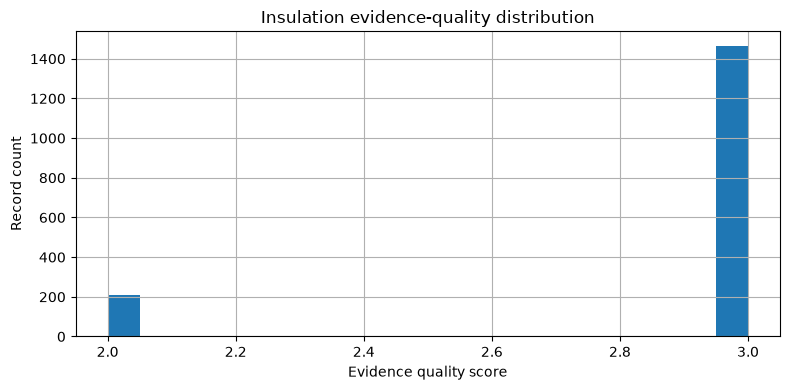

In [8]:
provenance_cols = [
    c for c in [
        "record_origin", "data_status", "evidence_quality_score",
        "lambda_level", "source_ids", "qa_flag_count", "qa_flags"
    ] if c in ins.columns
]

for col in provenance_cols:
    print(f"\\n--- {col} ---")
    if ins[col].dtype == "object":
        display(ins[col].fillna("<MISSING>").value_counts().head(30).to_frame("records"))
    else:
        display(ins[col].describe().to_frame())

if "evidence_quality_score" in ins.columns:
    plt.figure(figsize=(8, 4))
    ins["evidence_quality_score"].dropna().hist(bins=20)
    plt.xlabel("Evidence quality score")
    plt.ylabel("Record count")
    plt.title("Insulation evidence-quality distribution")
    plt.tight_layout()
    plt.show()


## 8. Group split integrity inside insulation subset

We preserve the existing `recommended_split` and `split_group_id` assignments for the first controlled comparison.

We must check that a split group never appears in more than one split after filtering. We must not randomly split individual variants.


In [9]:
split_counts = (
    ins["recommended_split"]
    .fillna("<MISSING>")
    .value_counts()
    .rename_axis("split")
    .reset_index(name="records")
)
display(split_counts)

split_group_table = (
    ins.groupby("recommended_split", dropna=False)
       .agg(
           records=("variant_id", "count"),
           products=("product_id", "nunique"),
           groups=("split_group_id", "nunique")
       )
       .reset_index()
)
display(split_group_table)

group_split_counts = ins.groupby("split_group_id")["recommended_split"].nunique(dropna=False)
cross_split_groups = group_split_counts[group_split_counts > 1]

print("Groups appearing in multiple splits:", len(cross_split_groups))
if len(cross_split_groups):
    display(
        ins[ins["split_group_id"].isin(cross_split_groups.index)]
        [["split_group_id", "product_id", "variant_id", "recommended_split"]]
        .sort_values("split_group_id")
    )
else:
    print("PASS: no split_group_id crosses train/validation/test within insulation subset.")


,split,records
0,train,1465
1,validation,168
2,test,41


,recommended_split,records,products,groups
0,test,41,3,3
1,train,1465,58,57
2,validation,168,9,9


Groups appearing in multiple splits: 0
PASS: no split_group_id crosses train/validation/test within insulation subset.


## 9. Duplicate and related-variant checks

Exact duplicate rows and repeated identifiers are checked separately. Multiple variants under one product are expected, but they must remain grouped during model evaluation.


In [10]:
duplicate_rows = int(ins.duplicated().sum())
duplicate_record_ids = int(ins["record_id"].duplicated().sum()) if "record_id" in ins else None
duplicate_variant_ids = int(ins["variant_id"].duplicated().sum())
duplicate_product_variant_pairs = (
    int(ins.duplicated(["product_id", "variant_id"]).sum())
    if {"product_id", "variant_id"}.issubset(ins.columns) else None
)

duplicate_summary = pd.DataFrame({
    "check": [
        "Exact duplicate rows",
        "Duplicate record_id",
        "Duplicate variant_id",
        "Duplicate product_id + variant_id pairs"
    ],
    "count": [
        duplicate_rows,
        duplicate_record_ids,
        duplicate_variant_ids,
        duplicate_product_variant_pairs
    ]
})
display(duplicate_summary)

variants_per_product = (
    ins.groupby("product_id")
       .agg(variants=("variant_id", "count"), families=("material_family", "nunique"))
       .sort_values("variants", ascending=False)
)
display(variants_per_product.head(25))


,check,count
0,Exact duplicate rows,0
1,Duplicate record_id,0
2,Duplicate variant_id,0
3,Duplicate product_id + variant_id pairs,0


,variants,families
product_id,,
HIRSCH_MAXISOL_ECA_ACERMI_24_081_1679,87,1
HIRSCH_CELLOMUR_ULTRA_ACERMI_12_081_795,78,1
HIRSCH_CELLOCEM_ULTRA_PRIMAIRE_ECA_ACERMI_24_081_1685,77,1
CAVAC_JETFIB_OUATE_ACERMI_14_D_130_929,62,1
IGLOO_FRANCE_CELLULOSE_ACERMI_12_D_157_784,59,1
ETEX_MULTITHERM31_ACERMI_26_009_1867,57,1
HIRSCH_STISOL_3000_ECA_ACERMI_24_081_1661,57,1
KNAUF_EXPERT_LRR_035_ACERMI_02_016_144,53,1
URSA_E_URSA_FACADE_32_P_ACERMI_03_058_169,53,1


## 10. Suitability of the insulation subset for each ML task

This is a readiness screen, not model training. The checks below count usable targets and available input coverage. The final feature list must be defined separately for each task.


In [11]:
def count_non_missing(column):
    return int(ins[column].notna().sum()) if column in ins.columns else 0

task_readiness = pd.DataFrame([
    {
        "ML task": "Thermal conductivity regression",
        "target": "target_thermal_conductivity_W_mK",
        "target_records": count_non_missing("target_thermal_conductivity_W_mK"),
        "notes": "Exclude conductivity, thermal resistance and thickness from inputs to avoid direct/derived leakage."
    },
    {
        "ML task": "Material classification",
        "target": "material_family",
        "target_records": count_non_missing("material_family"),
        "notes": "Inspect product/group counts per family; tiny classes may not support reliable grouped evaluation."
    },
    {
        "ML task": "Material clustering",
        "target": "None (unsupervised)",
        "target_records": len(ins),
        "notes": "Needs a defensible shared feature set and enough non-missing property coverage."
    },
    {
        "ML task": "Anomaly detection",
        "target": "None (unsupervised)",
        "target_records": len(ins),
        "notes": "Compare like with like; separate material-family effects from genuinely unusual records."
    }
])
display(task_readiness)

print("Regression target distribution:")
if "target_thermal_conductivity_W_mK" in ins.columns:
    display(ins["target_thermal_conductivity_W_mK"].describe().to_frame())


,ML task,target,target_records,notes
0,Thermal conductivity regression,target_thermal_conductivity_W_mK,1614,"Exclude conductivity, thermal resistance and t..."
1,Material classification,material_family,1674,Inspect product/group counts per family; tiny ...
2,Material clustering,None (unsupervised),1674,Needs a defensible shared feature set and enou...
3,Anomaly detection,None (unsupervised),1674,Compare like with like; separate material-fami...


Regression target distribution:


,target_thermal_conductivity_W_mK
count,1614.000000
mean,0.033616
std,0.008787
min,0.019000
25%,0.031000
50%,0.034000
75%,0.035000
max,0.100000


## 11. Export audit outputs (without changing the source dataset)

The notebook writes audit reports to a new folder under the ML engine. It does not overwrite the source CSV or existing model artifacts.


In [12]:
OUTPUT_DIR = PROJECT_ROOT / "06_AI_Performance_Engine" / "02_ML_Engine" / "04_Evaluation" / "reports" / "insulation_dataset_audit_v1"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

summary.to_csv(OUTPUT_DIR / "insulation_dataset_summary_v1.csv", index=False)
family_balance.to_csv(OUTPUT_DIR / "insulation_family_balance_v1.csv", index=False)
manufacturer_balance.to_csv(OUTPUT_DIR / "insulation_manufacturer_balance_v1.csv", index=False)
property_coverage.to_csv(OUTPUT_DIR / "insulation_property_coverage_v1.csv", index=False)
split_group_table.to_csv(OUTPUT_DIR / "insulation_split_summary_v1.csv", index=False)
task_readiness.to_csv(OUTPUT_DIR / "insulation_ml_task_readiness_v1.csv", index=False)

audit_json = {
    "audit_version": "1.0.0",
    "dataset_file": DATASET_PATH.name,
    "filter": {"column": "material_category_group", "value": INSULATION_GROUP},
    "source_rows": int(len(df)),
    "insulation_rows": int(len(ins)),
    "insulation_products": int(ins["product_id"].nunique()),
    "insulation_variants": int(ins["variant_id"].nunique()),
    "insulation_manufacturers": int(ins["manufacturer"].nunique()),
    "insulation_families": int(ins["material_family"].nunique()),
    "cross_split_group_count": int(len(cross_split_groups)),
    "source_dataset_modified": False,
    "model_training_performed": False
}
with open(OUTPUT_DIR / "insulation_dataset_audit_summary_v1.json", "w", encoding="utf-8") as f:
    json.dump(audit_json, f, indent=2)

print("Audit outputs saved to:", OUTPUT_DIR)
print(json.dumps(audit_json, indent=2))


Audit outputs saved to: D:\02_LEARNING\02_Masters_IAAC_AI_Architecture\10-Term_01\03-Research Studio\SpecSynth_AI\06_AI_Performance_Engine\02_ML_Engine\04_Evaluation\reports\insulation_dataset_audit_v1
{
  "audit_version": "1.0.0",
  "dataset_file": "SpecSynth_ML_variants_v1.5.0.csv",
  "filter": {
    "column": "material_category_group",
    "value": "A_thermal_insulation"
  },
  "source_rows": 1941,
  "insulation_rows": 1674,
  "insulation_products": 70,
  "insulation_variants": 1674,
  "insulation_manufacturers": 34,
  "insulation_families": 16,
  "cross_split_group_count": 0,
  "source_dataset_modified": false,
  "model_training_performed": false
}


## 12. Final review — complete after running all cells

Before model training, review and record:

1. Which insulation families have enough independent products and split groups?
2. Which families are too small for reliable family-level evaluation?
3. Which technical properties have sufficient coverage?
4. Which provenance statuses should be eligible for each model?
5. Are there any split-group leakage issues?
6. Is the conductivity target distribution broad enough across train, validation and test?
7. Which features are scientifically valid for each task?

**Do not proceed to training until the executed outputs have been reviewed.** The next step will use this evidence to define separate, leakage-safe feature pipelines for the four insulation models.
